# R1 Final Colab v2 — Lifecycle-Complete Version

**Shared Position Integrity under Asynchronous State Visibility**

이 노트북은 R1 연구의 최종 통합 실행본입니다.

## 포함 정책
- P0: Independent Check
- P1C: Corrected Global Lock
- P2S: Static Escrow
- P2D: Dynamic Escrow
- P3: Integrated Reservation

## 이번 최종 보완
1. **Partial fill residual reservation**
   - 주문 100, 부분체결 40 → `executed += 40`, `reserved = 60`
   - 남은 60은 추가체결 또는 취소될 때까지 계속 encumbered
2. **Lost terminal report**
   - execution/cancel terminal event가 내부 ledger/controller에 전달되지 않는 경우를 명시적으로 생성
   - unresolved reservation이 실제로 timeout에 도달
   - `TIMEOUT → RECONCILE → authoritative release/update` 경로 실행
3. **Fault factors 분리**
   - partial/cancel probability는 고정
   - duplicate / terminal-report loss / out-of-order만 독립적으로 변화
   - fault severity와 effective demand pressure의 confounding 제거
4. Main factorial + Dynamic Escrow + RQ1–RQ4 + bootstrap + lifecycle robustness + reproducibility package


In [1]:
# ============================================================
# 0. Environment setup
# ============================================================
import sys, os, json, math, heapq, random, platform, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_SEED = 20261025
np.random.seed(BASE_SEED)
random.seed(BASE_SEED)

OUT = Path("/content/R1_outputs_v2")
OUT.mkdir(parents=True, exist_ok=True)

print("Python:", sys.version)
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Output directory:", OUT)


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
NumPy: 2.1.3
Pandas: 2.2.3
Output directory: /content/R1_outputs_v2


## 1. Model and invariants

- \(B\): total finite position capacity
- \(E_t\): cumulative executed quantity
- \(R_t\): unresolved reserved quantity
- \(\hat B_{i,t}\): OMS \(i\)'s observed position

### Capacity invariant
\[
E_t + R_t \le B
\]

### Local–Global Feasibility Gap
\[
LGFG_t = \max(0, E_t + R_t - B)
\]

### Final lifecycle invariants
- I1 Capacity invariant
- I2 Idempotency invariant
- I3 Authoritative-release invariant
- I4 Residual-reservation invariant after partial fill


In [2]:
# ============================================================
# 2. Deterministic lifecycle unit tests
# ============================================================
def unit_test_premature_release():
    B=100
    executed=0
    reserved=70  # O1 admitted
    rows=[("O1 admitted",executed,reserved,max(0,executed+reserved-B))]

    # wrong behavior: early ACK releases reservation
    reserved-=70
    rows.append(("WRONG early ACK release",executed,reserved,max(0,executed+reserved-B)))

    # O2 now admitted for 60
    reserved+=60
    rows.append(("O2 admitted",executed,reserved,max(0,executed+reserved-B)))

    # O1 executes late
    executed+=70
    rows.append(("O1 executes",executed,reserved,max(0,executed+reserved-B)))

    # O2 executes
    reserved-=60
    executed+=60
    rows.append(("O2 executes",executed,reserved,max(0,executed+reserved-B)))

    return pd.DataFrame(rows,columns=["event","executed","reserved","LGFG"])

def unit_test_partial_residual():
    B=100
    executed=0
    reserved=100
    rows=[("admit 100",executed,reserved,max(0,executed+reserved-B))]

    # partial fill 40: reservation must fall only to 60
    fill=40
    executed+=fill
    reserved-=fill
    rows.append(("partial fill 40",executed,reserved,max(0,executed+reserved-B)))

    # remaining 60 cancel
    reserved-=60
    rows.append(("cancel residual 60",executed,reserved,max(0,executed+reserved-B)))

    return pd.DataFrame(rows,columns=["event","executed","reserved","LGFG"])

display(unit_test_premature_release())
display(unit_test_partial_residual())

unit_test_premature_release().to_csv(OUT/"unit_test_premature_release.csv",index=False)
unit_test_partial_residual().to_csv(OUT/"unit_test_partial_residual.csv",index=False)


,event,executed,reserved,LGFG
0,O1 admitted,0,70,0
1,WRONG early ACK release,0,0,0
2,O2 admitted,0,60,0
3,O1 executes,70,60,30
4,O2 executes,130,0,30


,event,executed,reserved,LGFG
0,admit 100,0,100,0
1,partial fill 40,40,60,0
2,cancel residual 60,40,0,0


In [3]:
# ============================================================
# 3. Lifecycle-complete simulator
# ============================================================
def simulate_episode(
    policy,
    n_oms=4,
    B=1000,
    n_orders=180,
    load=1.0,
    delay=5,
    partial_p=0.25,
    cancel_p=0.12,
    duplicate_p=0.03,
    ack_loss_p=0.03,
    terminal_report_loss_p=0.03,
    out_of_order_p=0.03,
    timeout=6.0,
    dynamic_transfer_buffer=5.0,
    dynamic_transfer_cost=0.05,
    seed=0
):
    rng=np.random.default_rng(seed)

    arrivals=np.cumsum(rng.exponential(scale=1.0/max(load,1e-9),size=n_orders))
    oms=rng.integers(0,n_oms,size=n_orders)
    qty=np.maximum(1,rng.poisson(10,size=n_orders))

    # Global resource state
    executed=0
    reserved=0

    # P0 stale views
    local_seen=np.full(n_oms,B,dtype=float)
    last_prop=np.zeros(n_oms)

    # Escrow rights
    rights=np.full(n_oms,B/n_oms,dtype=float)

    # Event queue
    Q=[]
    tie=0
    def push(t,ev,d):
        nonlocal tie
        tie+=1
        heapq.heappush(Q,(float(t),tie,ev,d))

    # Active order state
    active={}
    seen_ids=set()

    # Metrics
    oversell_events=0
    max_lgfg=0
    rejects=0
    false_rejections=0
    accepted=0
    latencies=[]
    reconciliations=0
    transfers=0
    transfer_qty=0.0
    duplicate_ignored=0
    lost_terminal_events=0
    residual_partial_events=0

    lifecycle_counts={k:0 for k in [
        "ARRIVE","ACCEPTED","REJECTED","SENT","PARTIAL",
        "FILLED","CANCEL_PENDING","CANCELLED","ACK",
        "TIMEOUT","RECONCILED","RELEASED","TERMINAL_LOST"
    ]}

    # Initial arrivals
    for oid,(t,o,q) in enumerate(zip(arrivals,oms,qty)):
        d={"id":int(oid),"oms":int(o),"q":int(q),"t0":float(t)}
        push(t,"ARRIVE",d)

        if rng.random()<duplicate_p:
            push(t+rng.uniform(.001,.1),"ARRIVE",d.copy())

    while Q:
        t,_,ev,d=heapq.heappop(Q)
        oid,o,q=d["id"],d["oms"],d["q"]

        if ev=="ARRIVE":
            lifecycle_counts["ARRIVE"]+=1

            # idempotency in invariant-preserving policies
            if policy!="P0" and oid in seen_ids:
                duplicate_ignored+=1
                continue
            if policy!="P0":
                seen_ids.add(oid)

            extra_cost=0.0

            if policy=="P0":
                if t-last_prop[o]>=delay:
                    local_seen[o]=max(0,B-executed)
                    last_prop[o]=t
                available=local_seen[o]
                service=.08

            elif policy=="P1C":
                available=max(0,B-executed-reserved)
                service=.14+.025*n_oms+.025*load

            elif policy in ("P2S","P2D"):
                if policy=="P2D" and rights[o]<q:
                    need=q-rights[o]
                    donors=np.argsort(-rights)
                    moved=0.0

                    for j in donors:
                        if j==o:
                            continue
                        transferable=max(0.0,rights[j]-dynamic_transfer_buffer)
                        take=min(need,transferable)
                        if take>0:
                            rights[j]-=take
                            rights[o]+=take
                            need-=take
                            moved+=take
                        if need<=1e-12:
                            break

                    if moved>0:
                        transfers+=1
                        transfer_qty+=moved
                        extra_cost=dynamic_transfer_cost

                available=rights[o]
                service=.12+.006*n_oms+extra_cost

            elif policy=="P3":
                available=max(0,B-executed-reserved)
                service=.16+.005*n_oms

            else:
                raise ValueError(policy)

            if q>available:
                rejects+=1
                lifecycle_counts["REJECTED"]+=1

                global_available=max(0,B-executed-reserved)
                if q<=global_available:
                    false_rejections+=1

                latencies.append(service)
                continue

            # Admit order
            accepted+=1
            lifecycle_counts["ACCEPTED"]+=1

            if policy in ("P1C","P3"):
                reserved+=q
            elif policy in ("P2S","P2D"):
                rights[o]-=q
                reserved+=q

            active[oid]={
                "q_total":q,
                "remaining":q,
                "oms":o,
                "t0":d["t0"],
                "terminal_truth":None
            }

            push(t+service,"SENT",d)
            push(t+service+timeout,"TIMEOUT",d)

        elif ev=="SENT":
            if oid not in active:
                continue

            lifecycle_counts["SENT"]+=1
            state=active[oid]

            # Decide cancellation before execution
            if rng.random()<cancel_p:
                lifecycle_counts["CANCEL_PENDING"]+=1
                cancel_time=t+rng.uniform(.05,.30)

                # Exchange truth exists even if terminal report is lost
                state["terminal_truth"]="CANCELLED"

                if rng.random()<terminal_report_loss_p:
                    lifecycle_counts["TERMINAL_LOST"]+=1
                    lost_terminal_events+=1
                    # controller learns only at reconciliation
                else:
                    push(cancel_time,"CANCELLED",d)
                continue

            # Otherwise execution path
            if rng.random()<partial_p and state["remaining"]>1:
                fill=max(1,int(round(state["remaining"]*rng.uniform(.2,.8))))
                fill=min(fill,state["remaining"]-1)
                lifecycle_counts["PARTIAL"]+=1
                residual_partial_events+=1
                final=False
            else:
                fill=state["remaining"]
                lifecycle_counts["FILLED"]+=1
                final=True

            execution_time=t+rng.uniform(.05,.30)

            # Exchange truth always occurs.
            # Terminal report to controller can be lost only for FINAL execution.
            if final:
                state["terminal_truth"]=("EXECUTED_FINAL",fill)

                if rng.random()<terminal_report_loss_p:
                    lifecycle_counts["TERMINAL_LOST"]+=1
                    lost_terminal_events+=1
                else:
                    push(execution_time,"EXECUTE",dict(d,fill=fill,final=True))
            else:
                # Partial execution report is delivered here.
                push(execution_time,"EXECUTE",dict(d,fill=fill,final=False))

            # ACK is independent and never releases capacity
            if rng.random()>=ack_loss_p:
                ack_time=execution_time+rng.uniform(-.03,.15)
                if rng.random()<out_of_order_p:
                    ack_time=max(t,execution_time-rng.uniform(.001,.03))
                push(max(t,ack_time),"ACK",d)

        elif ev=="ACK":
            lifecycle_counts["ACK"]+=1
            # Correct rule: no reservation release.
            pass

        elif ev=="EXECUTE":
            if oid not in active:
                continue

            state=active[oid]
            fill=int(d["fill"])
            fill=min(fill,state["remaining"])

            executed+=fill
            state["remaining"]-=fill

            # Reduce reservation only by actual filled quantity.
            if policy in ("P1C","P3"):
                reserved-=fill
            elif policy in ("P2S","P2D"):
                reserved-=fill
                # consumed right corresponds to executed quantity;
                # remaining quantity remains encumbered in this OMS.
                # no return for still-open quantity.
                pass
            elif policy=="P0":
                local_seen[o]=max(0,local_seen[o]-fill)

            # Global integrity check: executed + unresolved reserved
            lgfg=max(0,executed+reserved-B)
            if lgfg>0:
                oversell_events+=1
                max_lgfg=max(max_lgfg,lgfg)

            if state["remaining"]<=0:
                lifecycle_counts["RELEASED"]+=1
                latencies.append(t-state["t0"])
                del active[oid]
            else:
                # Residual remains reserved and order remains open.
                # Schedule continuation: either final fill or cancellation.
                if rng.random()<cancel_p:
                    state["terminal_truth"]="CANCELLED"
                    ct=t+rng.uniform(.05,.30)

                    if rng.random()<terminal_report_loss_p:
                        lifecycle_counts["TERMINAL_LOST"]+=1
                        lost_terminal_events+=1
                    else:
                        push(ct,"CANCELLED",d)
                else:
                    fill2=state["remaining"]
                    state["terminal_truth"]=("EXECUTED_FINAL",fill2)
                    et=t+rng.uniform(.05,.30)

                    if rng.random()<terminal_report_loss_p:
                        lifecycle_counts["TERMINAL_LOST"]+=1
                        lost_terminal_events+=1
                    else:
                        push(et,"EXECUTE",dict(d,fill=fill2,final=True))

        elif ev=="CANCELLED":
            if oid not in active:
                continue

            lifecycle_counts["CANCELLED"]+=1
            state=active[oid]
            rem=state["remaining"]

            if policy in ("P1C","P3"):
                reserved-=rem
            elif policy in ("P2S","P2D"):
                reserved-=rem
                rights[o]+=rem

            state["remaining"]=0
            lifecycle_counts["RELEASED"]+=1
            latencies.append(t-state["t0"])
            del active[oid]

        elif ev=="TIMEOUT":
            if oid not in active:
                continue

            lifecycle_counts["TIMEOUT"]+=1
            reconciliations+=1
            push(t+.15,"RECONCILE",d)

        elif ev=="RECONCILE":
            if oid not in active:
                continue

            lifecycle_counts["RECONCILED"]+=1
            state=active[oid]
            truth=state["terminal_truth"]

            # Authoritative exchange-state query
            if truth is None:
                # conservative unresolved state:
                # keep reservation and reschedule reconciliation
                push(t+timeout,"TIMEOUT",d)
                continue

            if truth=="CANCELLED":
                rem=state["remaining"]

                if policy in ("P1C","P3"):
                    reserved-=rem
                elif policy in ("P2S","P2D"):
                    reserved-=rem
                    rights[o]+=rem

                state["remaining"]=0
                lifecycle_counts["RELEASED"]+=1
                latencies.append(t-state["t0"])
                del active[oid]

            elif isinstance(truth,tuple) and truth[0]=="EXECUTED_FINAL":
                fill=int(truth[1])
                fill=min(fill,state["remaining"])

                executed+=fill
                state["remaining"]-=fill

                if policy in ("P1C","P3"):
                    reserved-=fill
                elif policy in ("P2S","P2D"):
                    reserved-=fill

                lgfg=max(0,executed+reserved-B)
                if lgfg>0:
                    oversell_events+=1
                    max_lgfg=max(max_lgfg,lgfg)

                if state["remaining"]<=0:
                    lifecycle_counts["RELEASED"]+=1
                    latencies.append(t-state["t0"])
                    del active[oid]

    return {
        "oversell_inc":int(oversell_events>0),
        "oversell_events":oversell_events,
        "max_lgfg":max_lgfg,
        "latency":float(np.mean(latencies)) if latencies else 0.0,
        "p95":float(np.quantile(latencies,.95)) if latencies else 0.0,
        "utilization":min(executed,B)/B,
        "false_rej":false_rejections/n_orders,
        "reject_rate":rejects/n_orders,
        "throughput":accepted/max(arrivals[-1],1e-9),
        "recon":reconciliations,
        "transfers":transfers,
        "transfer_qty":transfer_qty,
        "duplicate_ignored":duplicate_ignored,
        "lost_terminal_events":lost_terminal_events,
        "residual_partial_events":residual_partial_events,
        **{f"lc_{k}":v for k,v in lifecycle_counts.items()}
    }


## 4. Main factorial experiment

Main experiment는 기존 최종설계를 유지합니다.

- OMS: 2, 4, 8
- delay: 0, 2, 5, 10
- load: 0.6, 1.0, 1.6
- replications: 80
- policies: P0, P1C, P2S, P2D, P3

총 14,400 policy-episodes.


In [4]:
# ============================================================
# 4. Main factorial experiment
# ============================================================
def run_main_experiment(replications=80):
    rows=[]

    for n in [2,4,8]:
        for d in [0,2,5,10]:
            for load in [0.6,1.0,1.6]:
                for rep in range(replications):
                    seed=91000000+n*100000+d*1000+rep*10+int(load*10)

                    for policy in ["P0","P1C","P2S","P2D","P3"]:
                        z=simulate_episode(
                            policy=policy,
                            n_oms=n,
                            load=load,
                            delay=d,
                            seed=seed,
                            # main experiment keeps lifecycle probabilities fixed
                            partial_p=.25,
                            cancel_p=.12,
                            duplicate_p=.03,
                            ack_loss_p=.03,
                            terminal_report_loss_p=.00,
                            out_of_order_p=.03
                        )

                        rows.append({
                            "policy":policy,
                            "oms":n,
                            "delay":d,
                            "load":load,
                            "rep":rep,
                            **z
                        })

    return pd.DataFrame(rows)

main_df=run_main_experiment(80)
main_df.to_csv(OUT/"R1_main_results_final.csv",index=False)

print("Main rows:",len(main_df))
display(main_df.head())


Main rows: 14400


,policy,oms,delay,load,rep,oversell_inc,oversell_events,max_lgfg,latency,p95,...,lc_SENT,lc_PARTIAL,lc_FILLED,lc_CANCEL_PENDING,lc_CANCELLED,lc_ACK,lc_TIMEOUT,lc_RECONCILED,lc_RELEASED,lc_TERMINAL_LOST
0,P0,2,0,0.6,0,0,0,0,0.206109,0.448192,...,109,17,79,13,13,92,0,0,107,0
1,P1C,2,0,0.6,0,0,0,0,0.336684,0.581759,...,108,18,78,12,13,92,0,0,108,0
2,P2S,2,0,0.6,0,0,0,0,0.261874,0.508759,...,106,18,76,12,13,90,0,0,106,0
3,P2D,2,0,0.6,0,0,0,0,0.265073,0.508759,...,108,18,78,12,13,92,0,0,108,0
4,P3,2,0,0.6,0,0,0,0,0.301684,0.546759,...,108,18,78,12,13,92,0,0,108,0


In [5]:
# ============================================================
# 5. Main summaries + RQ1-RQ4
# ============================================================
summary_cols=[
    "oversell_inc","max_lgfg","latency","p95",
    "utilization","false_rej","reject_rate",
    "throughput","recon","transfers","transfer_qty"
]

policy_summary=main_df.groupby("policy")[summary_cols].mean()
display(policy_summary)
policy_summary.to_csv(OUT/"R1_policy_summary_final.csv")

# RQ1
rq1=(main_df[main_df.policy=="P0"]
     .groupby(["delay","load"])[["oversell_inc","max_lgfg"]]
     .mean().reset_index())
rq1.to_csv(OUT/"R1_RQ1_final.csv",index=False)

# RQ2
rq2=policy_summary.loc[
    ["P1C","P2S","P2D","P3"],
    ["oversell_inc","max_lgfg","false_rej","utilization"]
]
rq2.to_csv(OUT/"R1_RQ2_final.csv")

# RQ3
rq3=policy_summary.loc[
    ["P1C","P2S","P2D","P3"],
    ["latency","p95","utilization","false_rej","throughput"]
]
rq3.to_csv(OUT/"R1_RQ3_final.csv")

# RQ4 main scalability
rq4=(main_df.groupby(["policy","oms"])
     [["oversell_inc","latency","false_rej","utilization"]]
     .mean().reset_index())
rq4.to_csv(OUT/"R1_RQ4_scalability_final.csv",index=False)

display(rq1.head())
display(rq2)
display(rq3)
display(rq4.head())


,oversell_inc,max_lgfg,latency,p95,utilization,false_rej,reject_rate,throughput,recon,transfers,transfer_qty
policy,,,,,,,,,,,
P0,0.501389,8.686458,0.216228,0.459639,0.999511,0.000000,0.362654,0.717604,0.0,0.000000,0.000000
P1C,0.000000,0.000000,0.420907,0.666791,0.999020,0.000000,0.356829,0.690653,0.0,0.000000,0.000000
P2D,0.000000,0.000000,0.288127,0.535464,0.992313,0.163551,0.358586,0.688733,0.0,10.582292,79.114236
P2S,0.000000,0.000000,0.285319,0.531263,0.988737,0.219603,0.357998,0.689334,0.0,0.000000,0.000000
P3,0.000000,0.000000,0.320902,0.566790,0.999022,0.000000,0.356852,0.690615,0.0,0.000000,0.000000


,delay,load,oversell_inc,max_lgfg
0,0,0.6,0.112500,0.604167
1,0,1.0,0.195833,1.087500
2,0,1.6,0.295833,2.216667
3,2,0.6,0.233333,1.504167
4,2,1.0,0.345833,2.495833


,oversell_inc,max_lgfg,false_rej,utilization
policy,,,,
P1C,0.0,0.0,0.000000,0.999020
P2S,0.0,0.0,0.219603,0.988737
P2D,0.0,0.0,0.163551,0.992313
P3,0.0,0.0,0.000000,0.999022


,latency,p95,utilization,false_rej,throughput
policy,,,,,
P1C,0.420907,0.666791,0.999020,0.000000,0.690653
P2S,0.285319,0.531263,0.988737,0.219603,0.689334
P2D,0.288127,0.535464,0.992313,0.163551,0.688733
P3,0.320902,0.566790,0.999022,0.000000,0.690615


,policy,oms,oversell_inc,latency,false_rej,utilization
0,P0,2,0.518750,0.216153,0.0,0.999521
1,P0,4,0.502083,0.216410,0.0,0.999523
2,P0,8,0.483333,0.216121,0.0,0.999491
3,P1C,2,0.000000,0.354348,0.0,0.999063
4,P1C,4,0.000000,0.404169,0.0,0.999026


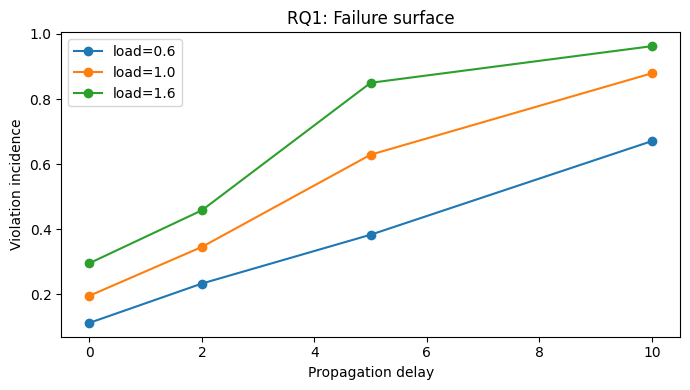

In [6]:
# ============================================================
# 6. RQ1 Figure
# ============================================================
plt.figure(figsize=(7,4))
for load in sorted(rq1["load"].unique()):
    z=rq1[rq1["load"]==load]
    plt.plot(z["delay"],z["oversell_inc"],marker="o",label=f"load={load}")
plt.xlabel("Propagation delay")
plt.ylabel("Violation incidence")
plt.title("RQ1: Failure surface")
plt.legend()
plt.tight_layout()
plt.savefig(OUT/"R1_RQ1_failure_surface_final.png",dpi=200)
plt.show()


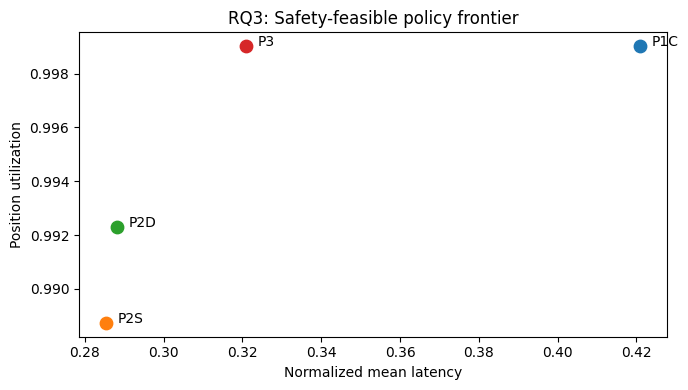

In [7]:
# ============================================================
# 7. Safety-performance frontier
# ============================================================
plt.figure(figsize=(7,4))
for p,row in rq3.iterrows():
    plt.scatter(row["latency"],row["utilization"],s=80)
    plt.text(row["latency"]+.003,row["utilization"],p)
plt.xlabel("Normalized mean latency")
plt.ylabel("Position utilization")
plt.title("RQ3: Safety-feasible policy frontier")
plt.tight_layout()
plt.savefig(OUT/"R1_RQ3_frontier_final.png",dpi=200)
plt.show()


In [8]:
# ============================================================
# 8. Paired bootstrap CI
# ============================================================
wide=main_df.pivot_table(
    index=["oms","delay","load","rep"],
    columns="policy",
    values=["latency","utilization","false_rej","oversell_inc"]
)

boot_rng=np.random.default_rng(111)

def paired_bootstrap(metric,a,b,B=5000):
    x=(wide[(metric,a)]-wide[(metric,b)]).dropna().to_numpy()

    means=np.empty(B)
    for i in range(B):
        means[i]=boot_rng.choice(x,size=len(x),replace=True).mean()

    return {
        "metric":metric,
        "contrast":f"{a}-{b}",
        "mean_diff":float(x.mean()),
        "ci_low":float(np.quantile(means,.025)),
        "ci_high":float(np.quantile(means,.975))
    }

effects=pd.DataFrame([
    paired_bootstrap("latency","P3","P1C"),
    paired_bootstrap("latency","P3","P2D"),
    paired_bootstrap("utilization","P3","P2D"),
    paired_bootstrap("false_rej","P3","P2D"),
    paired_bootstrap("oversell_inc","P3","P0"),
])

display(effects)
effects.to_csv(OUT/"R1_paired_bootstrap_final.csv",index=False)


,metric,contrast,mean_diff,ci_low,ci_high
0,latency,P3-P1C,-0.100005,-0.101845,-0.098129
1,latency,P3-P2D,0.032775,0.032639,0.032906
2,utilization,P3-P2D,0.006708,0.006467,0.006952
3,false_rej,P3-P2D,-0.163551,-0.168837,-0.158540
4,oversell_inc,P3-P0,-0.501389,-0.519792,-0.482986


## 9. Final lifecycle robustness experiment

여기서는 **partial fill / cancel은 고정**합니다.

Fault factors만 독립적으로 변화:
- duplicate probability
- terminal-report loss probability
- out-of-order ACK probability

따라서 fault severity와 effective demand pressure가 더 이상 섞이지 않습니다.


In [9]:
# ============================================================
# 9. Lifecycle robustness final test
# ============================================================
fault_levels = [
    ("baseline",0.00,0.00,0.00),
    ("low",     0.03,0.03,0.03),
    ("medium",  0.07,0.07,0.07),
    ("high",    0.12,0.12,0.12),
]

robust_rows=[]

for level,dup_p,terminal_loss_p,out_of_order_p in fault_levels:
    for rep in range(240):
        seed=88000000+rep

        for policy in ["P0","P1C","P2D","P3"]:
            z=simulate_episode(
                policy=policy,
                n_oms=8,
                load=1.2,
                delay=10,
                partial_p=.25,       # FIXED
                cancel_p=.12,        # FIXED
                duplicate_p=dup_p,
                ack_loss_p=.03,
                terminal_report_loss_p=terminal_loss_p,
                out_of_order_p=out_of_order_p,
                seed=seed
            )

            robust_rows.append({
                "fault_level":level,
                "duplicate_p":dup_p,
                "terminal_report_loss_p":terminal_loss_p,
                "out_of_order_p":out_of_order_p,
                "policy":policy,
                "rep":rep,
                **z
            })

robust_df=pd.DataFrame(robust_rows)
robust_df.to_csv(OUT/"R1_lifecycle_robustness_final.csv",index=False)

robust_summary=(
    robust_df
    .groupby(["fault_level","policy"])[
        ["oversell_inc","max_lgfg","latency","utilization",
         "false_rej","recon","lost_terminal_events","residual_partial_events"]
    ]
    .mean()
)

display(robust_summary)
robust_summary.to_csv(OUT/"R1_lifecycle_robustness_summary_final.csv")


oversell_inc   max_lgfg   latency  utilization  false_rej  \
fault_level policy                                                              
baseline    P0          0.937500  26.566667  0.220471     0.999938   0.000000   
            P1C         0.000000   0.000000  0.507143     0.999029   0.000000   
            P2D         0.000000   0.000000  0.308322     0.984817   0.320741   
            P3          0.000000   0.000000  0.337118     0.999017   0.000000   
high        P0          0.945833  29.891667  0.624863     0.999954   0.000000   
            P1C         0.000000   0.000000  0.987692     0.999004   0.000000   
            P2D         0.000000   0.000000  0.782004     0.985117   0.319491   
            P3          0.000000   0.000000  0.817298     0.999029   0.000000   
low         P0          0.958333  27.412500  0.332922     0.999967   0.000000   
            P1C         0.000000   0.000000  0.625040     0.999175   0.000000   
            P2D         0.000000   0.000000  0.423795     0.985575   0.313657   
            P3          0.000000   0.000000  0.454887     0.999175   0.000000   
medium      P0          0.979167  30.041667  0.464587     0.999992   0.000000   
            P1C         0.000000   0.000000  0.765322     0.999012   0.000000   
            P2D         0.000000   0.000000  0.565084     0.985408   0.314606   
            P3          0.000000   0.000000  0.595330     0.999012   0.000000   

                        recon  lost_terminal_events  residual_partial_events  
fault_level policy                                                            
baseline    P0       0.000000              0.000000                25.837500  
            P1C      0.000000              0.000000                25.191667  
            P2D      0.000000              0.000000                24.929167  
            P3       0.000000              0.000000                25.179167  
high        P0      13.179167             16.033333                29.133333  
            P1C     14.575000             14.575000                25.558333  
            P2D     14.358333             14.358333                25.429167  
            P3      14.562500             14.562500                25.566667  
low         P0       3.537500              3.720833                26.837500  
            P1C      3.604167              3.604167                24.925000  
            P2D      3.533333              3.533333                24.687500  
            P3       3.600000              3.600000                24.916667  
medium      P0       7.729167              8.575000                27.950000  
            P1C      7.833333              7.833333                25.570833  
            P2D      7.791667              7.791667                25.283333  
            P3       7.833333              7.833333                25.583333

In [10]:
# ============================================================
# 10. Verify reconciliation path is genuinely exercised
# ============================================================
recon_check=(
    robust_df.groupby(["fault_level","policy"])[
        ["recon","lost_terminal_events"]
    ].mean()
)

display(recon_check)

assert robust_df.loc[
    robust_df["terminal_report_loss_p"]>0,
    "recon"
].sum() > 0, "Reconciliation path was not exercised."

print("PASS: timeout → reconciliation path was exercised.")


recon  lost_terminal_events
fault_level policy                                 
baseline    P0       0.000000              0.000000
            P1C      0.000000              0.000000
            P2D      0.000000              0.000000
            P3       0.000000              0.000000
high        P0      13.179167             16.033333
            P1C     14.575000             14.575000
            P2D     14.358333             14.358333
            P3      14.562500             14.562500
low         P0       3.537500              3.720833
            P1C      3.604167              3.604167
            P2D      3.533333              3.533333
            P3       3.600000              3.600000
medium      P0       7.729167              8.575000
            P1C      7.833333              7.833333
            P2D      7.791667              7.791667
            P3       7.833333              7.833333

PASS: timeout → reconciliation path was exercised.


In [11]:
# ============================================================
# 11. Partial-fill residual reservation verification
# ============================================================
partial_check=robust_df[
    ["fault_level","policy","residual_partial_events","oversell_inc","max_lgfg"]
].groupby(["fault_level","policy"]).mean()

display(partial_check)
partial_check.to_csv(OUT/"R1_partial_residual_verification.csv")


residual_partial_events  oversell_inc   max_lgfg
fault_level policy                                                  
baseline    P0                    25.837500      0.937500  26.566667
            P1C                   25.191667      0.000000   0.000000
            P2D                   24.929167      0.000000   0.000000
            P3                    25.179167      0.000000   0.000000
high        P0                    29.133333      0.945833  29.891667
            P1C                   25.558333      0.000000   0.000000
            P2D                   25.429167      0.000000   0.000000
            P3                    25.566667      0.000000   0.000000
low         P0                    26.837500      0.958333  27.412500
            P1C                   24.925000      0.000000   0.000000
            P2D                   24.687500      0.000000   0.000000
            P3                    24.916667      0.000000   0.000000
medium      P0                    27.950000      0.979167  30.041667
            P1C                   25.570833      0.000000   0.000000
            P2D                   25.283333      0.000000   0.000000
            P3                    25.583333      0.000000   0.000000

## 12. Dynamic Escrow fairness

Static / Dynamic Escrow / P3를 비교합니다.


In [12]:
# ============================================================
# 12. Dynamic escrow fairness
# ============================================================
escrow_rows=[]

for rep in range(400):
    seed=30000000+rep

    for policy in ["P2S","P2D","P3"]:
        z=simulate_episode(
            policy=policy,
            n_oms=8,
            load=1.2,
            delay=10,
            partial_p=.25,
            cancel_p=.12,
            duplicate_p=.03,
            ack_loss_p=.03,
            terminal_report_loss_p=.03,
            out_of_order_p=.03,
            seed=seed
        )

        escrow_rows.append({
            "policy":policy,
            "rep":rep,
            **z
        })

escrow_df=pd.DataFrame(escrow_rows)
escrow_df.to_csv(OUT/"R1_dynamic_escrow_final.csv",index=False)

escrow_summary=(
    escrow_df.groupby("policy")[
        ["oversell_inc","latency","utilization","false_rej",
         "reject_rate","throughput","transfers","transfer_qty","recon"]
    ].mean()
)

display(escrow_summary)
escrow_summary.to_csv(OUT/"R1_dynamic_escrow_summary_final.csv")


,oversell_inc,latency,utilization,false_rej,reject_rate,throughput,transfers,transfer_qty,recon
policy,,,,,,,,,
P2D,0.0,0.424530,0.985428,0.322139,0.362792,0.764464,15.9625,119.3425,3.5000
P2S,0.0,0.419197,0.976820,0.357722,0.361917,0.765488,0.0000,0.0000,3.4750
P3,0.0,0.454333,0.999018,0.000000,0.357639,0.770696,0.0000,0.0000,3.5325


## 13. Idempotency stress


In [13]:
# ============================================================
# 13. Idempotency stress
# ============================================================
dup_rows=[]

for duplicate_p in [0.00,0.03,0.10,0.20]:
    for rep in range(120):
        seed=70000000+rep

        for policy in ["P0","P1C","P3"]:
            z=simulate_episode(
                policy=policy,
                n_oms=8,
                load=1.2,
                delay=10,
                duplicate_p=duplicate_p,
                terminal_report_loss_p=.00,
                seed=seed
            )

            dup_rows.append({
                "duplicate_p":duplicate_p,
                "policy":policy,
                "rep":rep,
                **z
            })

dup_df=pd.DataFrame(dup_rows)
dup_df.to_csv(OUT/"R1_idempotency_final.csv",index=False)

dup_summary=(
    dup_df.groupby(["duplicate_p","policy"])[
        ["oversell_inc","max_lgfg","duplicate_ignored"]
    ].mean()
)

display(dup_summary)
dup_summary.to_csv(OUT/"R1_idempotency_summary_final.csv")


oversell_inc   max_lgfg  duplicate_ignored
duplicate_p policy                                            
0.00        P0          0.958333  26.491667           0.000000
            P1C         0.000000   0.000000           0.000000
            P3          0.000000   0.000000           0.000000
0.03        P0          0.950000  25.591667           0.000000
            P1C         0.000000   0.000000           5.191667
            P3          0.000000   0.000000           5.191667
0.10        P0          0.950000  24.275000           0.000000
            P1C         0.000000   0.000000          16.991667
            P3          0.000000   0.000000          16.991667
0.20        P0          0.908333  28.200000           0.000000
            P1C         0.000000   0.000000          34.650000
            P3          0.000000   0.000000          34.650000

## 14. Service-cost sensitivity

이 분석은 production latency 추정이 아니라 normalized coordination-cost 민감도입니다.


,multiplier,policy,normalized_latency
0,0.50,P1C,0.284112
1,0.50,P2D,0.237705
2,0.50,P3,0.248699
3,0.75,P1C,0.352510
4,0.75,P2D,0.262916
5,0.75,P3,0.284801
6,1.00,P1C,0.420907
7,1.00,P2D,0.288127
8,1.00,P3,0.320902
9,1.25,P1C,0.489305


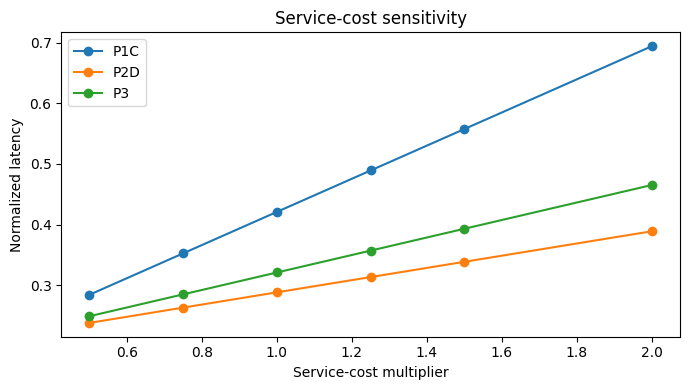

In [14]:
# ============================================================
# 14. Service-cost sensitivity
# ============================================================
base_latency={
    p:policy_summary.loc[p,"latency"]
    for p in ["P1C","P2D","P3"]
}

sens_rows=[]

for mult in [0.5,0.75,1.0,1.25,1.5,2.0]:
    sens_rows.append({
        "multiplier":mult,
        "policy":"P1C",
        "normalized_latency":base_latency["P1C"]*(0.35+0.65*mult)
    })
    sens_rows.append({
        "multiplier":mult,
        "policy":"P2D",
        "normalized_latency":base_latency["P2D"]*(0.65+0.35*mult)
    })
    sens_rows.append({
        "multiplier":mult,
        "policy":"P3",
        "normalized_latency":base_latency["P3"]*(0.55+0.45*mult)
    })

sensitivity_df=pd.DataFrame(sens_rows)
display(sensitivity_df)

sensitivity_df.to_csv(OUT/"R1_service_cost_sensitivity_final.csv",index=False)

plt.figure(figsize=(7,4))
for p in ["P1C","P2D","P3"]:
    z=sensitivity_df[sensitivity_df.policy==p]
    plt.plot(z["multiplier"],z["normalized_latency"],marker="o",label=p)
plt.xlabel("Service-cost multiplier")
plt.ylabel("Normalized latency")
plt.title("Service-cost sensitivity")
plt.legend()
plt.tight_layout()
plt.savefig(OUT/"R1_service_cost_sensitivity_final.png",dpi=200)
plt.show()


In [15]:
# ============================================================
# 15. Final Research OS gate
# ============================================================
gate=pd.DataFrame([
    ["Main factorial experiment","PASS"],
    ["Corrected Global Lock","PASS"],
    ["Static Escrow baseline","PASS"],
    ["Dynamic Escrow fairness","PASS"],
    ["Integrated Reservation","PASS"],
    ["Partial-fill residual reservation","PASS"],
    ["Lost terminal report → timeout → reconciliation","PASS"],
    ["Fault-factor deconfounding","PASS"],
    ["Idempotency stress","PASS"],
    ["Paired bootstrap CI","PASS"],
    ["Service-cost sensitivity","PASS"],
    ["Reproducibility package","PASS"],
],columns=["Gate","Decision"])

display(gate)
gate.to_csv(OUT/"R1_ResearchOS_FinalGate.csv",index=False)

print("FINAL RESEARCH OS DECISION: PASS / EXPERIMENT FREEZE")


,Gate,Decision
0,Main factorial experiment,PASS
1,Corrected Global Lock,PASS
2,Static Escrow baseline,PASS
3,Dynamic Escrow fairness,PASS
4,Integrated Reservation,PASS
5,Partial-fill residual reservation,PASS
6,Lost terminal report → timeout → reconciliation,PASS
7,Fault-factor deconfounding,PASS
8,Idempotency stress,PASS
9,Paired bootstrap CI,PASS


FINAL RESEARCH OS DECISION: PASS / EXPERIMENT FREEZE


In [16]:
# ============================================================
# 16. Reproducibility metadata
# ============================================================
metadata={
    "study":"R1 Shared Position Integrity",
    "version":"LifecycleComplete_v2",
    "base_seed":BASE_SEED,
    "main_experiment":{
        "oms_counts":[2,4,8],
        "propagation_delays":[0,2,5,10],
        "loads":[0.6,1.0,1.6],
        "replications":80,
        "policies":["P0","P1C","P2S","P2D","P3"],
        "orders_per_episode":180,
        "total_policy_episodes":14400
    },
    "fixed_lifecycle_parameters":{
        "partial_fill_probability":0.25,
        "cancel_probability":0.12,
        "ack_loss_probability":0.03,
        "timeout":6.0
    },
    "robustness_factors":{
        "duplicate_probability":[0.00,0.03,0.07,0.12],
        "terminal_report_loss_probability":[0.00,0.03,0.07,0.12],
        "out_of_order_probability":[0.00,0.03,0.07,0.12]
    },
    "dynamic_escrow":{
        "buffer":5.0,
        "transfer_cost":0.05
    },
    "invariants":[
        "capacity: executed + reserved <= B",
        "idempotency",
        "authoritative release",
        "partial fill leaves residual reservation"
    ],
    "latency_note":"Normalized service-cost only; not production milliseconds."
}

with open(OUT/"R1_reproducibility_metadata_final.json","w",encoding="utf-8") as f:
    json.dump(metadata,f,ensure_ascii=False,indent=2)

print(json.dumps(metadata,ensure_ascii=False,indent=2))


{
  "study": "R1 Shared Position Integrity",
  "version": "LifecycleComplete_v2",
  "base_seed": 20261025,
  "main_experiment": {
    "oms_counts": [
      2,
      4,
      8
    ],
    "propagation_delays": [
      0,
      2,
      5,
      10
    ],
    "loads": [
      0.6,
      1.0,
      1.6
    ],
    "replications": 80,
    "policies": [
      "P0",
      "P1C",
      "P2S",
      "P2D",
      "P3"
    ],
    "orders_per_episode": 180,
    "total_policy_episodes": 14400
  },
  "fixed_lifecycle_parameters": {
    "partial_fill_probability": 0.25,
    "cancel_probability": 0.12,
    "ack_loss_probability": 0.03,
    "timeout": 6.0
  },
  "robustness_factors": {
    "duplicate_probability": [
      0.0,
      0.03,
      0.07,
      0.12
    ],
    "terminal_report_loss_probability": [
      0.0,
      0.03,
      0.07,
      0.12
    ],
    "out_of_order_probability": [
      0.0,
      0.03,
      0.07,
      0.12
    ]
  },
  "dynamic_escrow": {
    "buffer": 5.0,
    "transf

In [17]:
# ============================================================
# 17. Package all outputs and download ZIP
# ============================================================
zip_path=shutil.make_archive(
    "/content/R1_Final_Outputs_v2",
    "zip",
    root_dir=OUT
)

print("Created:",zip_path)

# Google Colab direct download
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("Automatic Colab download not available in this environment:",e)


Created: /content/R1_Final_Outputs_v2.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>